# CTRL_FUT vs LCC_FUT after the CO₂ fix: vegetation state and spin-up lineage

**Question.** On the old chain (`check_CTRL_FUT_vs_LCC_FUT_vegetation_state.ipynb`) the FUT members were in very different vegetation states **everywhere** (unmodified land: ΔTOTVEGC −34 %, ΔTLAI −16 %, 87 % of the area with p < 0.05). Cause: CTRL_FUT had 20 land years after the CMIP6 2100 state, LCC_FUT 140, and the FUT land-only spin-up saw pre-industrial CO₂.
In the CO₂-fix chain **both** members get a 100-yr land-only spin-up (with the 2100 CO₂) and a 20-yr coupled spin-up. This notebook repeats the old checks on the new nudged runs and asks: **is there any vegetation difference left outside the land-cover-modified cells?**

| Section | What | Output |
|---|---|---|
| 0 | Spin-up lineage of both members, read from the history files and `lnd_in` | `lineage.csv` |
| A | 2001–2014 regional means of TLAI, TOTVEGC, TOTECOSYSC, GPP; Δ, Welch p, drift | `A_nudged_regional_means.csv`, `A_nudged_timeseries.png` |
| B | Maps and zonal means of LCC_FUT − CTRL_FUT, with cell-wise significance | `B_*.csv/png` |
| C | Every stage of both lineages on one axis, "land years since the CMIP6 2100 state" | `C_*.csv/png` |
| D | Outside the modified cells: paired test of the yearly differences + FDR, and old vs new chain | `D_*.csv` |

**Lineage (a, from `cases-scripts/run_aliases.csv`; re-checked from files in §0):**

| Stage | Branch | Case | Run | fsurdat | Starts from |
|---|---|---|---|---|---|
| `spinup` | shared | `…spinup_f19_f19-3` | 20 yr coupled, free | simyr2000 | NSSP585frc2 r.2100-01-01 |
| `landonly_CTRL` | CTRL | `I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023` | 100 yr land-only (cplhist of spinup) | simyr2000 | spinup r.0021 |
| `spinup_CTRL` | CTRL | `…spinup_ctrl…-20261025` | 20 yr coupled, free | simyr2000 | landonly_CTRL r.0101 |
| `CTRL_FUT` | CTRL | `…nudg_ctrl…-20261028` | nudged 2000–2014 | simyr2000 | spinup_CTRL r.0021 |
| `landonly_LCC` | LCC | `I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023` | 100 yr land-only (cplhist of spinup) | LPJ-GUESS | spinup r.0021 |
| `spinup_LCC` | LCC | `…spinup_lcc…-20261025` | 20 yr coupled, free | LPJ-GUESS | landonly_LCC r.0101 |
| `LCC_FUT` | LCC | `…nudg_lcc…-20261028` | nudged 2000–2014 | LPJ-GUESS | spinup_LCC r.0021 |

Both members now have **140 land years** since the CMIP6 2100 state. The surfdata differ only at 46–82°N, so a difference elsewhere can only come from the atmosphere (temperature, humidity, clouds and precipitation are not nudged) or from noise (b).

Evidence tags: **(a)** verified · **(b)** inference · **(c)** unverified. Run on Betzy in `lcc-env`. Annual means are cached in `check_CTRL_FUT_vs_LCC_FUT_vegetation_state-after-co2-fix_outputs/cache/`.


In [1]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy import stats
from cartopy.util import add_cyclic_point

ARCHIVE = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')
def archive_dir(case):
    moved = ARCHIVE / 'c-before-all-bvoc' / case
    return moved if moved.is_dir() else ARCHIVE / case
CASE_ROOT = Path('~/cases/BRL_FRST_XPSN').expanduser()
MASK_FILE = Path('lcc-modified-cells/modified_cells.nc')
OUT = Path('check_CTRL_FUT_vs_LCC_FUT_vegetation_state-after-co2-fix_outputs')
CACHE = OUT / 'cache'  # regenerable annual-mean .nc
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False  # True re-reads the history files

# Land-state lineage, oldest first. handed_on = model years completed when the restart was written for the next stage.
STAGES = pd.DataFrame([
    ('spinup',        'shared', 'NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3',            'coupled, free',      'simyr2000', 20),
    ('landonly_CTRL', 'CTRL',   'I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023',        'land-only, cplhist', 'simyr2000', 100),
    ('spinup_CTRL',   'CTRL',   'NF2100ssp585norbc_tropstratchem_spinup_ctrl_f19_f19-20261025', 'coupled, free',      'simyr2000', 20),
    ('CTRL_FUT',      'CTRL',   'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028',   'coupled, nudged',    'simyr2000', np.nan),
    ('landonly_LCC',  'LCC',    'I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023',         'land-only, cplhist', 'LPJGUESS',  100),
    ('spinup_LCC',    'LCC',    'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20261025',  'coupled, free',      'LPJGUESS',  20),
    ('LCC_FUT',       'LCC',    'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028',    'coupled, nudged',    'LPJGUESS',  np.nan),
], columns=['stage', 'branch', 'case', 'kind', 'surfdata', 'handed_on']).set_index('stage')

VARS = ['TLAI', 'TOTVEGC', 'TOTECOSYSC', 'GPP']
NUDGED_YEARS = (2001, 2014)  # 2000 = 12 spin-up months, dropped
ALPHA = 0.05
COLOR = {'shared': '0.35', 'CTRL': '#2C3990', 'LCC': '#BC423E'}

## 0. Lineage from the files

`Surface_dataset` and `case_id` come from the first `clm2.h0` file of each stage; `fsurdat`/`finidat` from `CaseDocs/lnd_in` (not available for the land-only case). With `use_init_interp = .true.` the file attribute `Initial_conditions_dataset` is only `finidat_interp_dest.nc`, so `finidat` must come from `lnd_in`.

In [2]:
NUDGED_CASES = set(STAGES.case[STAGES.kind.str.contains('nudged')])

def hist_files(case):
    files = sorted((archive_dir(case) / 'lnd/hist').glob('*.clm2.h0.*.nc'))
    if case in NUDGED_CASES:  # keep the analysis years (2000 = spin-up, dropped later)
        files = [f for f in files if int(f.name.split('.h0.')[1][:4]) <= NUDGED_YEARS[1]]
    if not files:
        raise FileNotFoundError(f'No clm2.h0 files for {case}')
    return files

def open_hist(path):
    return xr.open_dataset(path, decode_times=xr.coders.CFDatetimeCoder(use_cftime=True))

def namelist_value(case, key):
    for root in (CASE_ROOT, CASE_ROOT / 'BRL_FRST_XPSN_archive'):
        lnd_in = root / case / 'CaseDocs/lnd_in'
        if lnd_in.is_file():
            match = re.search(rf"^\s*{key}\s*=\s*'([^']*)'", lnd_in.read_text(), re.M)
            return Path(match.group(1)).name if match else 'not set'
    return 'no lnd_in'

rows = []
for stage, s in STAGES.iterrows():
    files = hist_files(s.case)
    with open_hist(files[0]) as first, open_hist(files[-1]) as last:
        rows.append(dict(stage=stage, branch=s.branch, kind=s.kind, files=len(files),
                         first_bound=str(first.time_bounds.values[0, 0])[:16],
                         last_bound=str(last.time_bounds.values[-1, 1])[:16],
                         case_id=first.attrs.get('case_id'), Surface_dataset=first.attrs.get('Surface_dataset'),
                         fsurdat=namelist_value(s.case, 'fsurdat'), finidat=namelist_value(s.case, 'finidat')))
lineage = pd.DataFrame(rows).set_index('stage')
lineage.to_csv(OUT / 'lineage.csv')
display(lineage)

for stage, s in STAGES.iterrows():
    found = lineage.loc[stage, 'Surface_dataset']
    assert s.surfdata in found, f'{stage}: expected {s.surfdata} surfdata, file says {found}'
    if lineage.loc[stage, 'case_id'] != s.case:
        print(f"⚠ {stage}: file case_id = {lineage.loc[stage, 'case_id']!r}, archive folder = {s.case!r}")

,branch,kind,files,first_bound,last_bound,case_id,Surface_dataset,fsurdat,finidat
stage,,,,,,,,,
spinup,shared,"coupled, free",20,0000-12-31 23:30,0021-01-01 00:00,NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,NSSP585frc2_f19_tn14_20191014.clm2.r.2100-01-0...
landonly_CTRL,CTRL,"land-only, cplhist",11,0000-12-31 23:30,0101-01-01 00:00,I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,NF2100ssp585norbc_tropstratchem_spinup_f19_f19...
spinup_CTRL,CTRL,"coupled, free",240,0000-12-31 23:30,0021-01-01 00:00,NF2100ssp585norbc_tropstratchem_spinup_ctrl_f1...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20...
CTRL_FUT,CTRL,"coupled, nudged",180,1999-12-31 23:30,2015-01-01 00:00,NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c...,NF2100ssp585norbc_tropstratchem_spinup_ctrl_f1...
landonly_LCC,LCC,"land-only, cplhist",11,0000-12-31 23:30,0101-01-01 00:00,I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-202...,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,NF2100ssp585norbc_tropstratchem_spinup_f19_f19...
spinup_LCC,LCC,"coupled, free",240,0000-12-31 23:30,0021-01-01 00:00,NF2100ssp585norbc_tropstratchem_spinup_lcc_f19...,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-202...
LCC_FUT,LCC,"coupled, nudged",180,1999-12-31 23:30,2015-01-01 00:00,NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f...,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc,NF2100ssp585norbc_tropstratchem_spinup_lcc_f19...


## Annual means and data checks

Annual means are weighted by the length of each `time_bounds` interval. Each interval goes to the year of its **midpoint**. The bounds start 30 min before the nominal start date, so taking the start would put January in the previous year. Years without 365 days of coverage are dropped. This removes, for example, the zero-length record at t = 0 in the land-only output.
Spatial weights are `area × landfrac`. Cell values are the grid-cell means as CLM writes them (b: over the landunits CLM averages each field on).

In [3]:
def annual_means(case):
    parts = []
    for f in hist_files(case):
        with open_hist(f) as ds:
            bounds = ds.time_bounds.values
            days = np.array([(end - start).total_seconds() / 86400 for start, end in bounds])
            years = np.array([(start + (end - start) / 2).year for start, end in bounds])
            calendar = bounds[0, 0].calendar
            parts.append(ds[VARS].load().assign_coords(year=('time', years), days=('time', days)))
            grid = ds[['area', 'landfrac']].load()
    ds = xr.concat(parts, 'time')
    if pd.Index(ds.time.values).duplicated().any():
        raise ValueError(f'{case}: duplicated time steps')
    covered = ds.days.groupby('year').sum()
    ann = (ds[VARS] * ds.days).groupby('year').sum(min_count=1) / covered
    ann = ann.sel(year=covered.year[np.abs(covered - 365) < 0.5])
    for v in VARS:
        ann[v].attrs = ds[v].attrs
    ann = ann.assign(area=grid.area, landfrac=grid.landfrac)
    ann.attrs.update(case=case, calendar=calendar,
                     method='clm2.h0 -> annual mean weighted by time_bounds length, interval assigned to its midpoint year; years with <365 d dropped')
    return ann

def load_stage(stage):
    path = CACHE / f'annual_{stage}.nc'
    if path.is_file() and not REBUILD_CACHE:
        return xr.open_dataset(path).load()
    ann = annual_means(STAGES.loc[stage, 'case'])
    ann.to_netcdf(path)
    return ann

ANN = {stage: load_stage(stage) for stage in STAGES.index}

ref = ANN['CTRL_FUT']
checks = pd.DataFrame([dict(
    stage=stage, years=f'{int(a.year[0])}–{int(a.year[-1])}', n_years=a.sizes['year'],
    same_grid=np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon),
    same_area=bool(np.allclose(a.area, ref.area, equal_nan=True)),
    same_landfrac=bool(np.allclose(a.landfrac, ref.landfrac, equal_nan=True)),
    units=', '.join(a[v].attrs.get('units', '?') for v in VARS), calendar=a.attrs['calendar'])
    for stage, a in ANN.items()]).set_index('stage')
display(checks)
assert checks[['same_grid', 'same_area', 'same_landfrac']].all().all(), 'grids differ: do not compare'
assert checks.units.nunique() == 1 and (checks.calendar == 'noleap').all()

,years,n_years,same_grid,same_area,same_landfrac,units,calendar
stage,,,,,,,
spinup,1–20,20,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
landonly_CTRL,1–100,100,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
spinup_CTRL,1–20,20,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
CTRL_FUT,2000–2014,15,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
landonly_LCC,1–100,100,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
spinup_LCC,1–20,20,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap
LCC_FUT,2000–2014,15,True,True,True,"m^2/m^2, gC/m^2, gC/m^2, gC/m^2/s",noleap


In [4]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon), 'mask grid differs'
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
REGIONS = {
    'global land': LAND,
    'modified cells': LAND & mask,
    'all unmodified land': LAND & ~mask,
}
W = ref.area * ref.landfrac
SCALE = {'GPP': (86400 * 365, 'gC/m^2/yr')}

def scaled(ann, v):
    factor, units = SCALE.get(v, (1, ann[v].attrs.get('units', '?')))
    return ann[v] * factor, units

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def slope_per_decade(series):
    return 10 * np.polyfit(series.year.values.astype(float), series.values, 1)[0]

print({r: int(m.sum()) for r, m in REGIONS.items()}, '(land cells per region)')

{'global land': 5701, 'modified cells': 1152, 'all unmodified land': 4549} (land cells per region)


## A. Nudged runs, 2001–2014

Regional means for each year, then the 14-year mean, Δ = LCC_FUT − CTRL_FUT, Welch p on the 14 annual values, CTRL interannual SD, and each run's OLS drift (per decade, descriptive).
Nudging makes the two members share their weather, so the annual values are paired and autocorrelated; Welch p is only a rough guide (b).

In [5]:
y0, y1 = NUDGED_YEARS
NUD = {k: ANN[k].sel(year=slice(y0, y1)) for k in ('CTRL_FUT', 'LCC_FUT')}
assert all(n.sizes['year'] == y1 - y0 + 1 for n in NUD.values())

rows, SERIES = [], {}
for region in REGIONS:
    for v in VARS:
        (c, units), (l, _) = scaled(NUD['CTRL_FUT'], v), scaled(NUD['LCC_FUT'], v)
        c, l = regional_mean(c, region), regional_mean(l, region)
        SERIES[region, v] = c, l
        rows.append(dict(region=region, variable=v, units=units,
                         CTRL_FUT=float(c.mean()), LCC_FUT=float(l.mean()), delta=float(l.mean() - c.mean()),
                         delta_pct=float(100 * (l.mean() - c.mean()) / c.mean()),
                         p_welch=stats.ttest_ind(l.values, c.values, equal_var=False).pvalue,
                         ctrl_iav_sd=float(c.std(ddof=1)),
                         ctrl_drift_per_decade=slope_per_decade(c), lcc_drift_per_decade=slope_per_decade(l)))
table_A = pd.DataFrame(rows).set_index(['region', 'variable'])
table_A.to_csv(OUT / 'A_nudged_regional_means.csv')
display(table_A.round(3))

units   CTRL_FUT    LCC_FUT    delta  \
region              variable                                               
global land         TLAI          m^2/m^2      2.584      2.560   -0.023   
                    TOTVEGC        gC/m^2   7216.545   7272.408   55.863   
                    TOTECOSYSC     gC/m^2  26467.995  26464.904   -3.092   
                    GPP         gC/m^2/yr   1173.635   1165.623   -8.013   
modified cells      TLAI          m^2/m^2      2.520      2.365   -0.154   
                    TOTVEGC        gC/m^2   7266.006   7612.082  346.077   
                    TOTECOSYSC     gC/m^2  72717.176  72721.121    3.946   
                    GPP         gC/m^2/yr    972.179    923.397  -48.782   
all unmodified land TLAI          m^2/m^2      2.596      2.598    0.003   
                    TOTVEGC        gC/m^2   7206.908   7206.226   -0.682   
                    TOTECOSYSC     gC/m^2  17456.784  17452.321   -4.463   
                    GPP         gC/m^2/yr   1212.887   1212.818   -0.069   

                                delta_pct  p_welch  ctrl_iav_sd  \
region              variable                                      
global land         TLAI           -0.892    0.000        0.014   
                    TOTVEGC         0.774    0.000       14.535   
                    TOTECOSYSC     -0.012    0.607       16.291   
                    GPP            -0.683    0.007        7.422   
modified cells      TLAI           -6.124    0.000        0.022   
                    TOTVEGC         4.763    0.000       23.938   
                    TOTECOSYSC      0.005    0.708       23.539   
                    GPP            -5.018    0.000       23.726   
all unmodified land TLAI            0.098    0.646        0.015   
                    TOTVEGC        -0.009    0.889       12.866   
                    TOTECOSYSC     -0.026    0.625       23.825   
                    GPP            -0.006    0.979        7.102   

                                ctrl_drift_per_decade  lcc_drift_per_decade  
region              variable                                                 
global land         TLAI                        0.010                -0.001  
                    TOTVEGC                    33.602                31.283  
                    TOTECOSYSC                 38.648                35.828  
                    GPP                         4.996                 2.847  
modified cells      TLAI                        0.027                -0.002  
                    TOTVEGC                    56.236                41.780  
                    TOTECOSYSC                -54.348               -73.009  
                    GPP                        26.409                19.155  
all unmodified land TLAI                        0.006                -0.001  
                    TOTVEGC                    29.192                29.238  
                    TOTECOSYSC                 56.767                57.034  
                    GPP                         0.824                -0.330

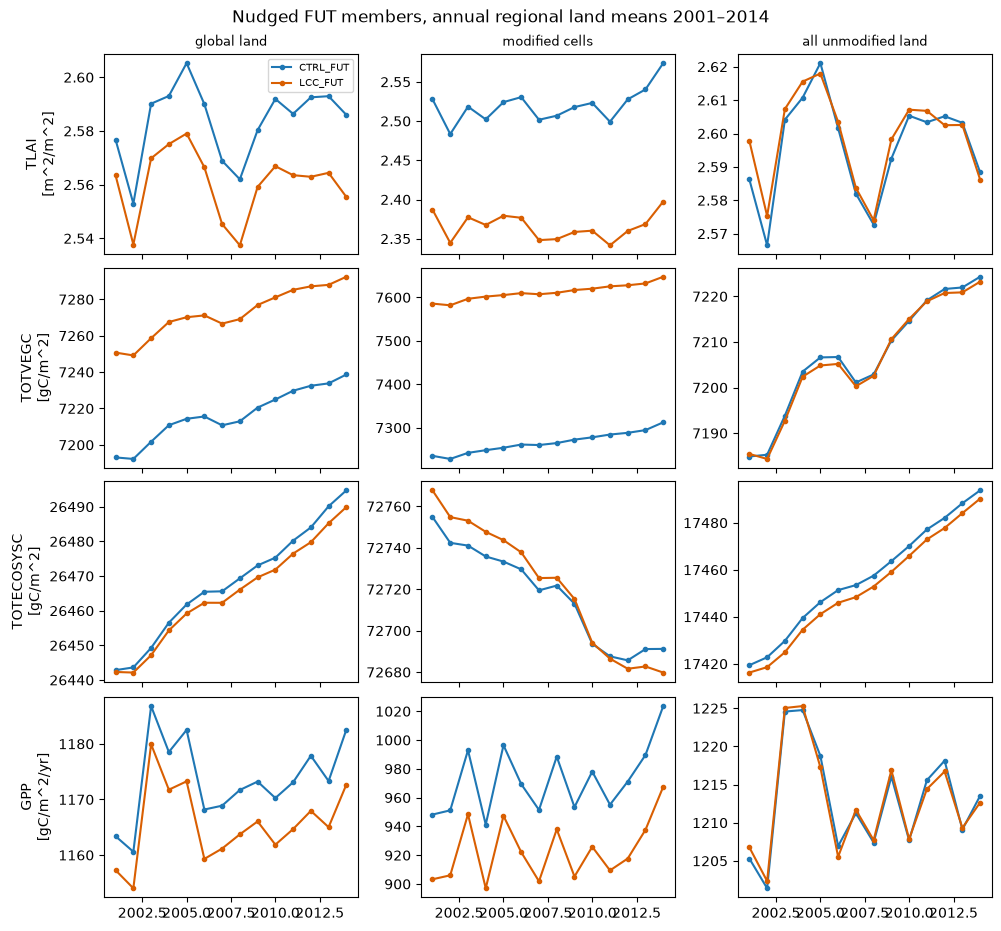

In [6]:
fig, axes = plt.subplots(len(VARS), len(REGIONS), figsize=(3.3 * len(REGIONS), 2.3 * len(VARS)),
                         sharex=True, layout='constrained')
for j, region in enumerate(REGIONS):
    for i, v in enumerate(VARS):
        ax = axes[i, j]
        c, l = SERIES[region, v]
        ax.plot(c.year, c, 'o-', ms=3, color=COLOR['CTRL'], label='CTRL_FUT')
        ax.plot(l.year, l, 'o-', ms=3, color=COLOR['LCC'], label='LCC_FUT')
        ax.set_title(region if i == 0 else '', fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{v}\n[{table_A.loc[(region, v), 'units']}]")
axes[0, 0].legend(fontsize=7)
fig.suptitle(f'Nudged FUT members, annual regional land means {y0}–{y1}')
fig.savefig(OUT / 'A_nudged_timeseries.png', dpi=150)
plt.show()

## B. Where do the members differ? Maps and zonal means, 2001–2014

Δ of the 14-year means; TOTVEGC and GPP as % of CTRL (cells with small CTRL values are masked). Grey hatching (`/////`): land cells **not** significant, cell-wise Welch p ≥ 0.05 on the 14 annual values (same look as the forcing maps, `plotting/forcing_maps.add_stippling` style "lines"; no FDR here). Unhatched land = p < 0.05. With no real difference, about 5 % of the area would be unhatched by chance. Magenta contour: modified cells.
The table gives the area-weighted mean Δ and the share of land area with p < 0.05 for each region.

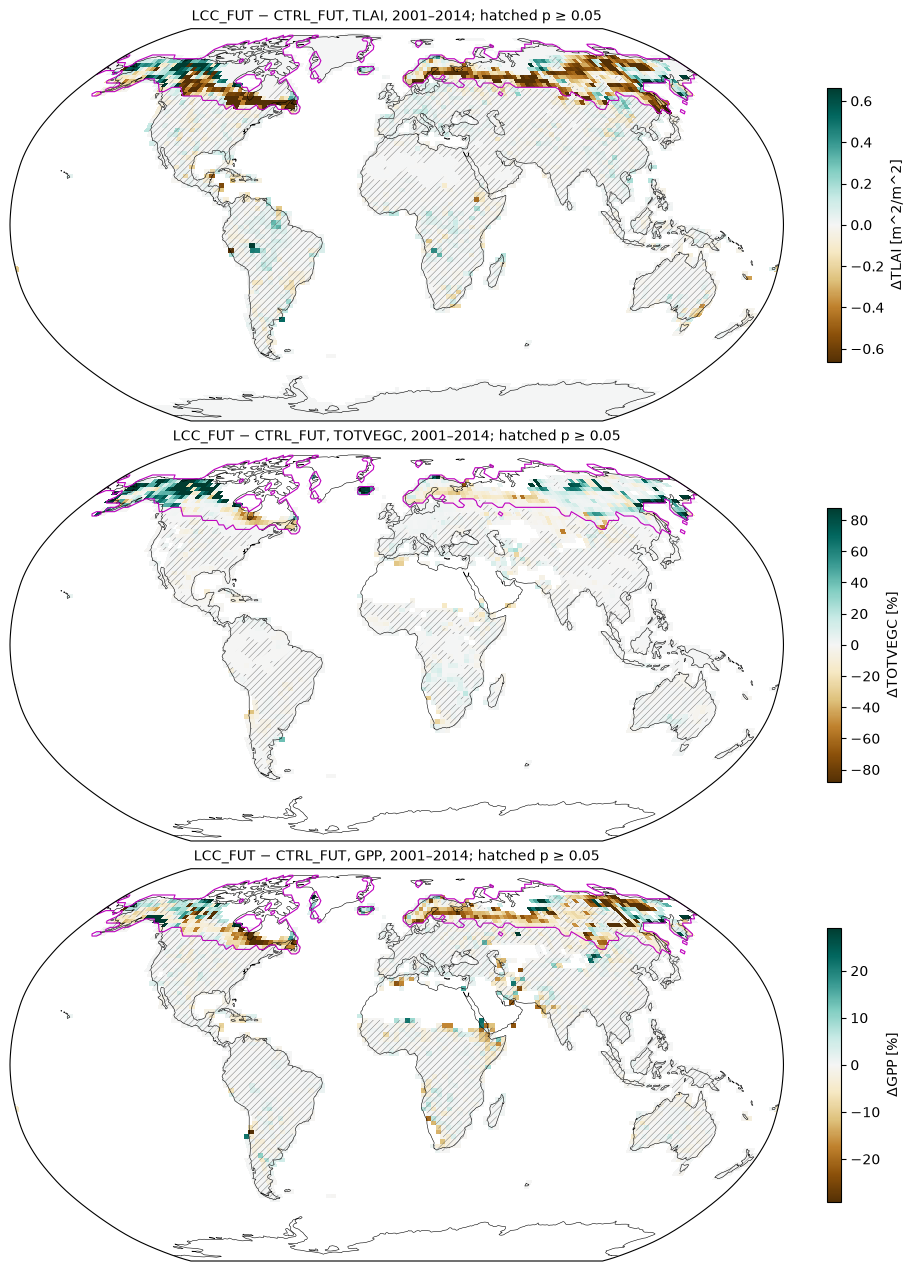

units  mean_delta  sig_area_frac  \
variable region                                                    
TLAI     global land          m^2/m^2      -0.023          0.100   
         modified cells       m^2/m^2      -0.154          0.565   
         all unmodified land  m^2/m^2       0.003          0.010   
TOTVEGC  global land                %       2.766          0.340   
         modified cells             %      17.578          0.906   
         all unmodified land        %      -0.185          0.227   
GPP      global land                %      -0.808          0.090   
         modified cells             %      -3.787          0.536   
         all unmodified land        %      -0.234          0.003   

                              sig_positive_frac  
variable region                                  
TLAI     global land                      0.028  
         modified cells                   0.147  
         all unmodified land              0.005  
TOTVEGC  global land                      0.174  
         modified cells                   0.527  
         all unmodified land              0.103  
GPP      global land                      0.020  
         modified cells                   0.118  
         all unmodified land              0.001

In [7]:
MAPS = [('TLAI', 'abs'), ('TOTVEGC', 'pct'), ('GPP', 'pct')]
MIN_BASE = {'TOTVEGC': 100.0, 'GPP': 30.0}  # gC/m^2 and gC/m^2/yr: below this, % is not shown
c_ann, l_ann = NUD['CTRL_FUT'], NUD['LCC_FUT']

def delta_map(v, kind):
    c, units = scaled(c_ann, v)
    l, _ = scaled(l_ann, v)
    cm = c.mean('year')
    d = l.mean('year') - cm
    if kind == 'pct':
        d, units = 100 * d / cm.where(cm > MIN_BASE[v]), '%'
    with warnings.catch_warnings(), np.errstate(all='ignore'):
        warnings.simplefilter('ignore')
        p = stats.ttest_ind(l.values, c.values, axis=0, equal_var=False).pvalue
    return d.where(LAND), xr.DataArray(p, coords=cm.coords), units

rows = []
fig, axes = plt.subplots(len(MAPS), 1, figsize=(10, 4.2 * len(MAPS)),
                         subplot_kw=dict(projection=ccrs.Robinson()), layout='constrained')
for ax, (v, kind) in zip(axes, MAPS):
    d, p, units = delta_map(v, kind)
    lim = float(np.nanpercentile(abs(d), 98))
    m = ax.pcolormesh(d.lon, d.lat, d, transform=ccrs.PlateCarree(), cmap='BrBG',
                      vmin=-lim, vmax=lim, shading='nearest')
    nonsig, lon_c = add_cyclic_point(((p >= ALPHA) & np.isfinite(d)).values.astype(float), coord=d.lon.values)
    hatch = ax.contourf(lon_c, d.lat, np.where(nonsig > 0.5, 1.0, np.nan), levels=[0.5, 1.5], colors='none',
                        hatches=['/////'], transform=ccrs.PlateCarree(), zorder=4)
    hatch.set_edgecolor('dimgrey')
    hatch.set_linewidth(0.0)
    hatch.set_hatch_linewidth(0.3)
    ax.contour(mask.lon, mask.lat, mask.astype(int), levels=[0.5], colors='m', linewidths=0.8,
               transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.4)
    ax.set_global()
    fig.colorbar(m, ax=ax, shrink=0.7, label=f'Δ{v} [{units}]')
    ax.set_title(f'LCC_FUT − CTRL_FUT, {v}, {y0}–{y1}; hatched p ≥ {ALPHA}', fontsize=10)
    for region in REGIONS:
        w = W.where(REGIONS[region] & np.isfinite(d))
        rows.append(dict(variable=v, units=units, region=region,
                         mean_delta=float((d * w).sum() / w.sum()),
                         sig_area_frac=float(w.where(p < ALPHA).sum() / w.sum()),
                         sig_positive_frac=float(w.where((p < ALPHA) & (d > 0)).sum() / w.sum())))
fig.savefig(OUT / 'B_delta_maps.png', dpi=150)
plt.show()

table_B = pd.DataFrame(rows).set_index(['variable', 'region'])
table_B.to_csv(OUT / 'B_delta_area_stats.csv')
display(table_B.round(3))

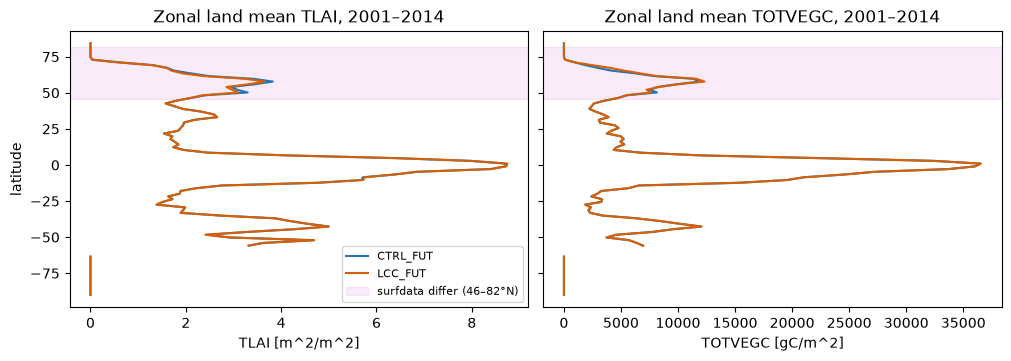

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout='constrained')
for ax, v in zip(axes, ['TLAI', 'TOTVEGC']):
    for name, ann in NUD.items():
        f, units = scaled(ann, v)
        f = f.mean('year')
        w = W.where(LAND & np.isfinite(f))
        ax.plot((f * w).sum('lon') / w.sum('lon'), f.lat, color=COLOR[name.split('_')[0]], label=name)
    ax.axhspan(46, 82, color='m', alpha=0.08, label='surfdata differ (46–82°N)')
    ax.set(xlabel=f'{v} [{units}]', title=f'Zonal land mean {v}, {y0}–{y1}')
axes[0].set_ylabel('latitude')
axes[0].legend(fontsize=8)
fig.savefig(OUT / 'B_zonal_means.png', dpi=150)
plt.show()

## C. Lineage: every stage on one axis

x = land years since the CMIP6 2100 state. Shared `spinup` 1–20, then each branch: land-only 21–120 → coupled spin-up 121–140 → nudged run 141–155 (2000–2014).
Only the years handed on to the next stage are plotted. Jumps at stage boundaries can come from a change in forcing (datm cplhist vs coupled; free vs nudged; surfdata switch) and are **not** drift (b). Look at the trend *within* a stage.
The table gives the OLS trend over the last 10 years of each stage, in % per decade of that stage's mean.

{'spinup': (1, 20), 'landonly_CTRL': (21, 120), 'spinup_CTRL': (121, 140), 'CTRL_FUT': (141, 155), 'landonly_LCC': (21, 120), 'spinup_LCC': (121, 140), 'LCC_FUT': (141, 155)}


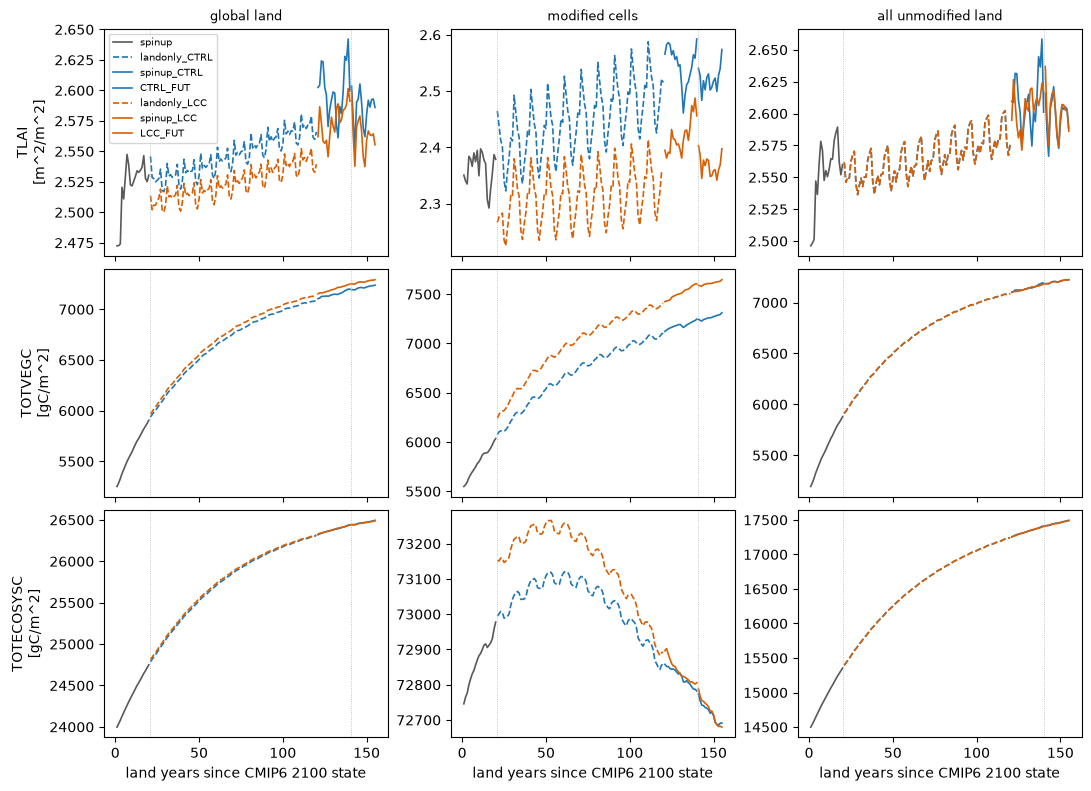

stage                           spinup  landonly_CTRL  spinup_CTRL  CTRL_FUT  \
variable   region                                                              
TLAI       all unmodified land    0.29          -0.04         1.83     -0.15   
           global land            0.07          -0.52         2.26      0.12   
           modified cells        -1.20          -3.04         4.55      1.51   
TOTECOSYSC all unmodified land    2.76           0.51         0.49      0.31   
           global land            1.48           0.22         0.24      0.14   
           modified cells         0.11          -0.13        -0.06     -0.08   
TOTVEGC    all unmodified land    5.52           0.55         0.88      0.35   
           global land            5.18           0.50         0.93      0.43   
           modified cells         3.52           0.22         1.21      0.80   

stage                           landonly_LCC  spinup_LCC  LCC_FUT  
variable   region                                                  
TLAI       all unmodified land         -0.04        0.37    -0.21  
           global land                 -0.48        0.89    -0.13  
           modified cells              -2.97        3.79     0.37  
TOTECOSYSC all unmodified land          0.51        0.39     0.32  
           global land                  0.21        0.20     0.13  
           modified cells              -0.15       -0.04    -0.11  
TOTVEGC    all unmodified land          0.55        0.55     0.36  
           global land                  0.49        0.70     0.39  
           modified cells               0.20        1.42     0.55

In [9]:
AXIS, end_of = {}, {'shared': 0}
for stage, s in STAGES.iterrows():
    ann = ANN[stage]
    start = 0 if s.branch == 'shared' else end_of.get(s.branch, end_of['shared'])
    n = ann.year - int(ann.year[0]) + 1
    if pd.notna(s.handed_on):
        assert int(n.max()) >= s.handed_on, f'{stage}: only {int(n.max())} complete years, {s.handed_on} handed on'
        ann = ANN[stage] = ann.sel(year=ann.year[n <= s.handed_on])
        n = n[n <= s.handed_on]
        end_of[s.branch] = start + int(s.handed_on)
    AXIS[stage] = start + n.values
print({k: (int(v[0]), int(v[-1])) for k, v in AXIS.items()})

C_REGIONS = list(REGIONS)
C_VARS = ['TLAI', 'TOTVEGC', 'TOTECOSYSC']
rows = []
fig, axes = plt.subplots(len(C_VARS), len(C_REGIONS), figsize=(3.6 * len(C_REGIONS), 2.6 * len(C_VARS)),
                         sharex=True, layout='constrained')
for j, region in enumerate(C_REGIONS):
    for i, v in enumerate(C_VARS):
        ax = axes[i, j]
        for stage, s in STAGES.iterrows():
            field, units = scaled(ANN[stage], v)
            series = regional_mean(field, region)
            ax.plot(AXIS[stage], series, color=COLOR[s.branch], lw=1.2,
                    ls='--' if 'land-only' in s.kind else '-', label=stage)
            last = series.isel(year=slice(-10, None))
            rows.append(dict(variable=v, region=region, stage=stage,
                             trend_pct_per_decade=100 * slope_per_decade(last) / float(last.mean())))
        for x in sorted(set(end_of.values()) - {0}):
            ax.axvline(x + 0.5, color='0.7', lw=0.6, ls=':')
        ax.set_title(region if i == 0 else '', fontsize=9)
        if j == 0:
            ax.set_ylabel(f'{v}\n[{units}]')
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('land years since CMIP6 2100 state')
fig.savefig(OUT / 'C_lineage_timeseries.png', dpi=150)
plt.show()

table_C = pd.DataFrame(rows).pivot_table(index=['variable', 'region'], columns='stage',
                                         values='trend_pct_per_decade')[list(STAGES.index)]
table_C.to_csv(OUT / 'C_last10yr_trend_pct_per_decade.csv')
display(table_C.round(2))

## D. Outside the modified cells: is any difference left?

Members share the nudged winds and surface pressure, so year *y* of LCC_FUT is paired with year *y* of CTRL_FUT (as in `analysis/stats.py`). For each cell: two-sided one-sample *t*-test of the 14 yearly differences, then Benjamini–Hochberg FDR (α_FDR = 0.10) **within each region**. With no real difference, ~5 % of the area has p < 0.05 and ~0 % passes FDR.
Regional rows: mean Δ of the yearly regional means, its 95 % CI over years, paired p. Extra regions: unmodified land in the tropics (30°S–30°N, where the old chain had its far-field signal) and unmodified land ≥ 45°N (next to the forest, where an atmospheric response is possible).
The last table compares unmodified land with the old chain (`check_CTRL_FUT_vs_LCC_FUT_vegetation_state_outputs/B_delta_area_stats.csv`, 2001–2009, Welch p).


In [10]:
import sys
sys.path.insert(0, str(Path.cwd().parents[1] / 'src'))
from boreal_forest_expansion.analysis.stats import cellwise_pvalue, fdr_mask

D_REGIONS = {**REGIONS,
             'unmodified land 30°S–30°N': LAND & ~mask & (abs(ref.lat) <= 30),
             'unmodified land ≥45°N': LAND & ~mask & (ref.lat >= 45)}

def rmean(field, m):
    w = W.where(m & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

rows, P = [], {}
for v in VARS:
    (c, units), (l, _) = scaled(NUD['CTRL_FUT'], v), scaled(NUD['LCC_FUT'], v)
    d = (l - c).where(LAND)                      # paired yearly differences
    p = cellwise_pvalue(d, 'year')
    P[v] = p
    for region, m in D_REGIONS.items():
        dy, base = rmean(d, m), float(rmean(c, m).mean())
        n = dy.sizes['year']
        w = W.where(m & np.isfinite(p))
        sig = fdr_mask(p, alpha=0.10, within=m)
        rows.append(dict(variable=v, region=region, units=units, n_cells=int(m.sum()),
                         CTRL_FUT=base, delta=float(dy.mean()), delta_pct=100 * float(dy.mean()) / base,
                         ci95=float(stats.t.ppf(0.975, n - 1) * dy.std(ddof=1) / np.sqrt(n)),
                         p_paired=float(stats.ttest_1samp(dy.values, 0).pvalue),
                         area_p05=float(w.where(p < 0.05).sum() / w.sum()),
                         area_fdr=float(w.where(sig).sum() / w.sum())))
table_D = pd.DataFrame(rows).set_index(['variable', 'region'])
table_D.to_csv(OUT / 'D_paired_fdr_by_region.csv')
pd.set_option('display.width', 220)
display(table_D.round(4))


/cluster/home/adelez/BOREAL-FOREST-EXPANSION/src/boreal_forest_expansion/analysis/stats.py:18: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return sps.ttest_1samp(x, 0.0, axis=-1, nan_policy="omit").pvalue
/cluster/home/adelez/BOREAL-FOREST-EXPANSION/src/boreal_forest_expansion/analysis/stats.py:18: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return sps.ttest_1samp(x, 0.0, axis=-1, nan_policy="omit").pvalue
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:660: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly i

units  n_cells    CTRL_FUT     delta  delta_pct    ci95  p_paired  area_p05  area_fdr
variable   region                                                                                                              
TLAI       global land                  m^2/m^2     5701      2.5835   -0.0230    -0.8915  0.0030    0.0000    0.3404    0.3154
           modified cells               m^2/m^2     1152      2.5198   -0.1543    -6.1235  0.0075    0.0000    0.9041    0.9195
           all unmodified land          m^2/m^2     4549      2.5959    0.0025     0.0980  0.0024    0.0420    0.2391    0.1460
           unmodified land 30°S–30°N    m^2/m^2     1514      3.3840    0.0047     0.1393  0.0031    0.0064    0.2594    0.1587
           unmodified land ≥45°N        m^2/m^2      670      2.1629    0.0009     0.0437  0.0029    0.4897    0.2604    0.2016
TOTVEGC    global land                   gC/m^2     5701   7216.5447   55.8633     0.7741  0.6325    0.0000    0.7033    0.7277
           modified cells                gC/m^2     1152   7266.0055  346.0768     4.7630  3.6427    0.0000    0.9572    0.9623
           all unmodified land           gC/m^2     4549   7206.9077   -0.6821    -0.0095  0.4163    0.0036    0.6493    0.6722
           unmodified land 30°S–30°N     gC/m^2     1514  10933.8186   -1.3048    -0.0119  0.7428    0.0022    0.6608    0.6827
           unmodified land ≥45°N         gC/m^2      670   4849.2922    1.0198     0.0210  0.8142    0.0180    0.7484    0.7912
TOTECOSYSC global land                   gC/m^2     5701  26467.9953   -3.0916    -0.0117  0.7067    0.0000    0.8854    0.9025
           modified cells                gC/m^2     1152  72717.1756    3.9458     0.0054  4.6271    0.0884    0.9907    0.9927
           all unmodified land           gC/m^2     4549  17456.7843   -4.4628    -0.0256  0.3599    0.0000    0.8620    0.8818
           unmodified land 30°S–30°N     gC/m^2     1514  19143.9190   -4.9506    -0.0259  0.5550    0.0000    0.8601    0.8755
           unmodified land ≥45°N         gC/m^2      670  27666.1402   -8.9016    -0.0322  1.4947    0.0000    0.8597    0.8938
GPP        global land                gC/m^2/yr     5701   1173.6353   -8.0126    -0.6827  0.6996    0.0000    0.2521    0.2211
           modified cells             gC/m^2/yr     1152    972.1790  -48.7821    -5.0178  2.1481    0.0000    0.8722    0.8871
           all unmodified land        gC/m^2/yr     4549   1212.8872   -0.0690    -0.0057  0.5733    0.7989    0.1407    0.0478
           unmodified land 30°S–30°N  gC/m^2/yr     1514   1641.8889    0.2165     0.0132  0.9647    0.6359    0.1602    0.0630
           unmodified land ≥45°N      gC/m^2/yr      670    960.3347    0.0331     0.0034  1.4918    0.9625    0.1484    0.0731

In [11]:
old = pd.read_csv('check_CTRL_FUT_vs_LCC_FUT_vegetation_state_outputs/B_delta_area_stats.csv').set_index(['variable', 'region'])
new = table_B   # same calculation as the old chain (Welch p, Δ of the period means; TOTVEGC, GPP in %)
cmp = pd.DataFrame({'old chain 2001–2009: mean Δ': old['mean_delta'], 'old: area p<0.05': old['sig_area_frac'],
                    'new chain 2001–2014: mean Δ': new['mean_delta'], 'new: area p<0.05': new['sig_area_frac']})
cmp['units'] = new['units']
cmp.to_csv(OUT / 'D_old_vs_new_chain.csv')
display(cmp.round(3))


old chain 2001–2009: mean Δ  old: area p<0.05  new chain 2001–2014: mean Δ  new: area p<0.05    units
variable region                                                                                                                    
TLAI     global land                               -0.394             0.520                       -0.023             0.100  m^2/m^2
         modified cells                            -0.277             0.649                       -0.154             0.565  m^2/m^2
         all unmodified land                       -0.416             0.495                        0.003             0.010  m^2/m^2
TOTVEGC  global land                              -24.220             0.884                        2.766             0.340        %
         modified cells                             9.033             0.964                       17.578             0.906        %
         all unmodified land                      -30.860             0.868                       -0.185             0.227        %
GPP      global land                              -10.598             0.485                       -0.808             0.090        %
         modified cells                            -5.337             0.600                       -3.787             0.536        %
         all unmodified land                      -11.617             0.463                       -0.234             0.003        %

## Summary (run 2026-11-02, outputs in `check_CTRL_FUT_vs_LCC_FUT_vegetation_state-after-co2-fix_outputs/`)

👉 **After the CO₂ fix the FUT members have the same vegetation state outside the modified cells.** The old-chain far-field difference is gone; the land-cover signal stays in the modified cells.

**1. Lineage (a, §0).** All 7 stages confirmed from the files (surfdata, case_id, finidat). Both members: 20 yr shared spin-up → 100 yr land-only → 20 yr coupled → nudged 2000–2014 (140 land years each).

**2. Regional Δ = LCC_FUT − CTRL_FUT, 2001–2014 (a, tables A and D):**

| Region | ΔTLAI | ΔTOTVEGC | ΔTOTECOSYSC | ΔGPP |
|---|---|---|---|---|
| all unmodified land, new chain | +0.10 % | −0.01 % | −0.03 % | −0.01 % |
| all unmodified land, old chain (2001–2009) | −16 % | −34 % | −21 % | −11 % |
| unmodified land 30°S–30°N | +0.14 % | −0.01 % | −0.03 % | +0.01 % |
| unmodified land ≥45°N | +0.04 % | +0.02 % | −0.03 % | +0.00 % |
| modified cells | −6.1 % | +4.8 % | +0.01 % | −5.0 % |

**3. Cell by cell (a, table D; interpretation b).**
- Fluxes and leaf area: on unmodified land, GPP is significant (FDR) in 5 % of the area and TLAI in 15 %. With Welch p on the period means (as in the old chain, table `D_old_vs_new_chain.csv`), TLAI and GPP are significant on 1 % and 0.3 % of unmodified land, against 49 % and 46 % on the old chain.
- Carbon pools: the paired test flags most of the unmodified area (TOTVEGC 67 %, TOTECOSYSC 88 % after FDR) although the differences are tiny (median |Δ| 0.5 % and 0.2 % per cell). The yearly differences of the pools are persistent (median lag-1 r = 0.46 for TOTVEGC), so the 14 years are not independent and the paired *t*-test overstates significance for slow pools (b). Use the size of Δ, not p, for pools.
- About 1 % of unmodified cells (53 for TOTVEGC, 54 for TLAI) differ by more than 10 %. They are low-biomass cells spread over all latitudes and mostly ≥3 cells from the forest, so they are not a land-cover response (b).

**4. Where they come from (my reading).** The two land-only spin-ups are almost identical outside the modified cells (max |ΔTOTVEGC| 1.9 gC m⁻² over the 100 years) (a). The small differences most likely start in the 20-year free-running coupled spin-ups, where the weather differs between the two members, and the slow carbon pools carry them into the nudged runs (b).

**5. Drift (a, table C).** Last-10-yr TOTVEGC trend on unmodified land: CTRL_FUT +0.35, LCC_FUT +0.36 % per decade (old chain: +4.3 and +11.4).

**For the paper:** the spin-up check can be stated as "outside the modified cells, LCC − CTRL differences in leaf area, vegetation and ecosystem carbon and GPP are below 0.15 % (FUT, 2001–2014)". The PD twin (`check_CTRL_PD_vs_LCC_PD…`) has not been made.
